## Import libraries

In [2]:
import numpy as np
import pandas as pd
from glob import glob
from obspy.geodetics.base import gps2dist_azimuth
import pygmt as pmt

import warnings
warnings.filterwarnings("ignore")

## Load the nearby station list

In [3]:
station_list_100km=pd.read_csv("/home/msseo/works/72.2025_Imsil_swarm/station_table/kma_stations_100km.csv", sep=",")
station_list_100km.head(5)

,Network,Code,Latitude,Longitude,Elevation
0,KS,KMC,35.98692,127.94262,0.0
1,KS,BAU,35.10270,127.59680,562.0
2,KS,BLGA,36.13920,127.30320,105.0
3,KS,BLLA,34.86460,127.46380,45.0
4,KS,BUYB,36.27260,126.92060,59.0


## Load event catalog

In [4]:
imsil_catalog=pd.read_csv("./event_catalog/event_catalog_utc.csv", sep=",")
imsil_catalog.head()

,Year,Month,Day,Hour,Minute,Second,Latitude,Longitude,Depth,Magnitude
0,2025,11,2,20,5,39,35.55,127.29,13,1.4
1,2025,11,2,20,6,25,35.55,127.29,12,1.4
2,2025,11,2,20,10,44,35.55,127.30,13,1.3
3,2025,11,2,20,23,39,35.56,127.30,13,1.5
4,2025,11,2,20,24,12,35.55,127.29,14,1.5


## Select the waveforms corresponding to nearby stations (HH+HG+EL)

In [5]:
HH_station_list, HG_station_list, EL_station_list=[], [], []

eventdir_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/kma_waveforms/20*"))
for eventdir in eventdir_list:
    # HH
    HH_list=glob(eventdir+"/*.v/SAC/HH/*HHZ*SAC")
    for sacfile in HH_list:
        code=sacfile.split("/")[-1].split(".")[1]
        if code in np.array(station_list_100km["Code"]):
            HH_station_list.append(code)
        
    # HG
    HG_list=glob(eventdir+"/*.a/SAC/HG/*HGZ*SAC")
    for sacfile in HG_list:
        code=sacfile.split("/")[-1].split(".")[1]
        if code in np.array(station_list_100km["Code"]):
            HG_station_list.append(code)
    
    # EL
    EL_list=glob(eventdir+"/*.v/SAC/EL/*ELZ*SAC")
    for sacfile in EL_list:
        code=sacfile.split("/")[-1].split(".")[1]
        if code in np.array(station_list_100km["Code"]):
            EL_station_list.append(code)
    
    
HH_station_list=list(set(HH_station_list))
HG_station_list=list(set(HG_station_list))
EL_station_list=list(set(EL_station_list))

In [6]:
print(len(HH_station_list))
print(len(HG_station_list))
print(len(EL_station_list))

16
54
4


### Remove duplicates (Priority HH > EL > HG)

In [7]:
EL_list_without_duplicates, HG_list_without_duplicates=[], []
for code in EL_station_list:
    if code not in HH_station_list:
        EL_list_without_duplicates.append(code)
        
for code in HG_station_list:
    if (code not in HH_station_list) and (code not in EL_station_list):
        HG_list_without_duplicates.append(code)
        
print(len(HG_list_without_duplicates))
print(len(EL_list_without_duplicates))
print(len(HH_station_list)+len(HG_list_without_duplicates)+len(EL_list_without_duplicates))

35
4
55


### Update station table information

In [8]:
used_station_list=[]
for code in HH_station_list:
    used_station_list.append(code)
for code in HG_list_without_duplicates:
    used_station_list.append(code)
for code in EL_list_without_duplicates:
    used_station_list.append(code)
    
print(len(used_station_list))

55


In [9]:
used_station_table=station_list_100km[station_list_100km["Code"].isin(used_station_list)].reset_index(drop=True)
used_station_table.head(5)

,Network,Code,Latitude,Longitude,Elevation
0,KS,BAU,35.1027,127.5968,562.0
1,KS,BLGA,36.1392,127.3032,105.0
2,KS,BLLA,34.8646,127.4638,45.0
3,KS,BUYB,36.2726,126.9206,59.0
4,KS,CGPA,34.8768,126.9710,144.0


In [11]:
sensor_type_list=[]
for i in range(len(used_station_table)):
    code=used_station_table["Code"][i]
    if code in HH_station_list:
        sensor_type_list.append("HH")
    elif code in HG_list_without_duplicates:
        sensor_type_list.append("HG")
    else:
        sensor_type_list.append("EL")

used_station_table["Sensor"]=sensor_type_list
# used_station_table.to_csv("/home/msseo/works/72.2025_Imsil_swarm/station_table/used_stations_100km.csv", index=False)

## Draw the map with sensor type information

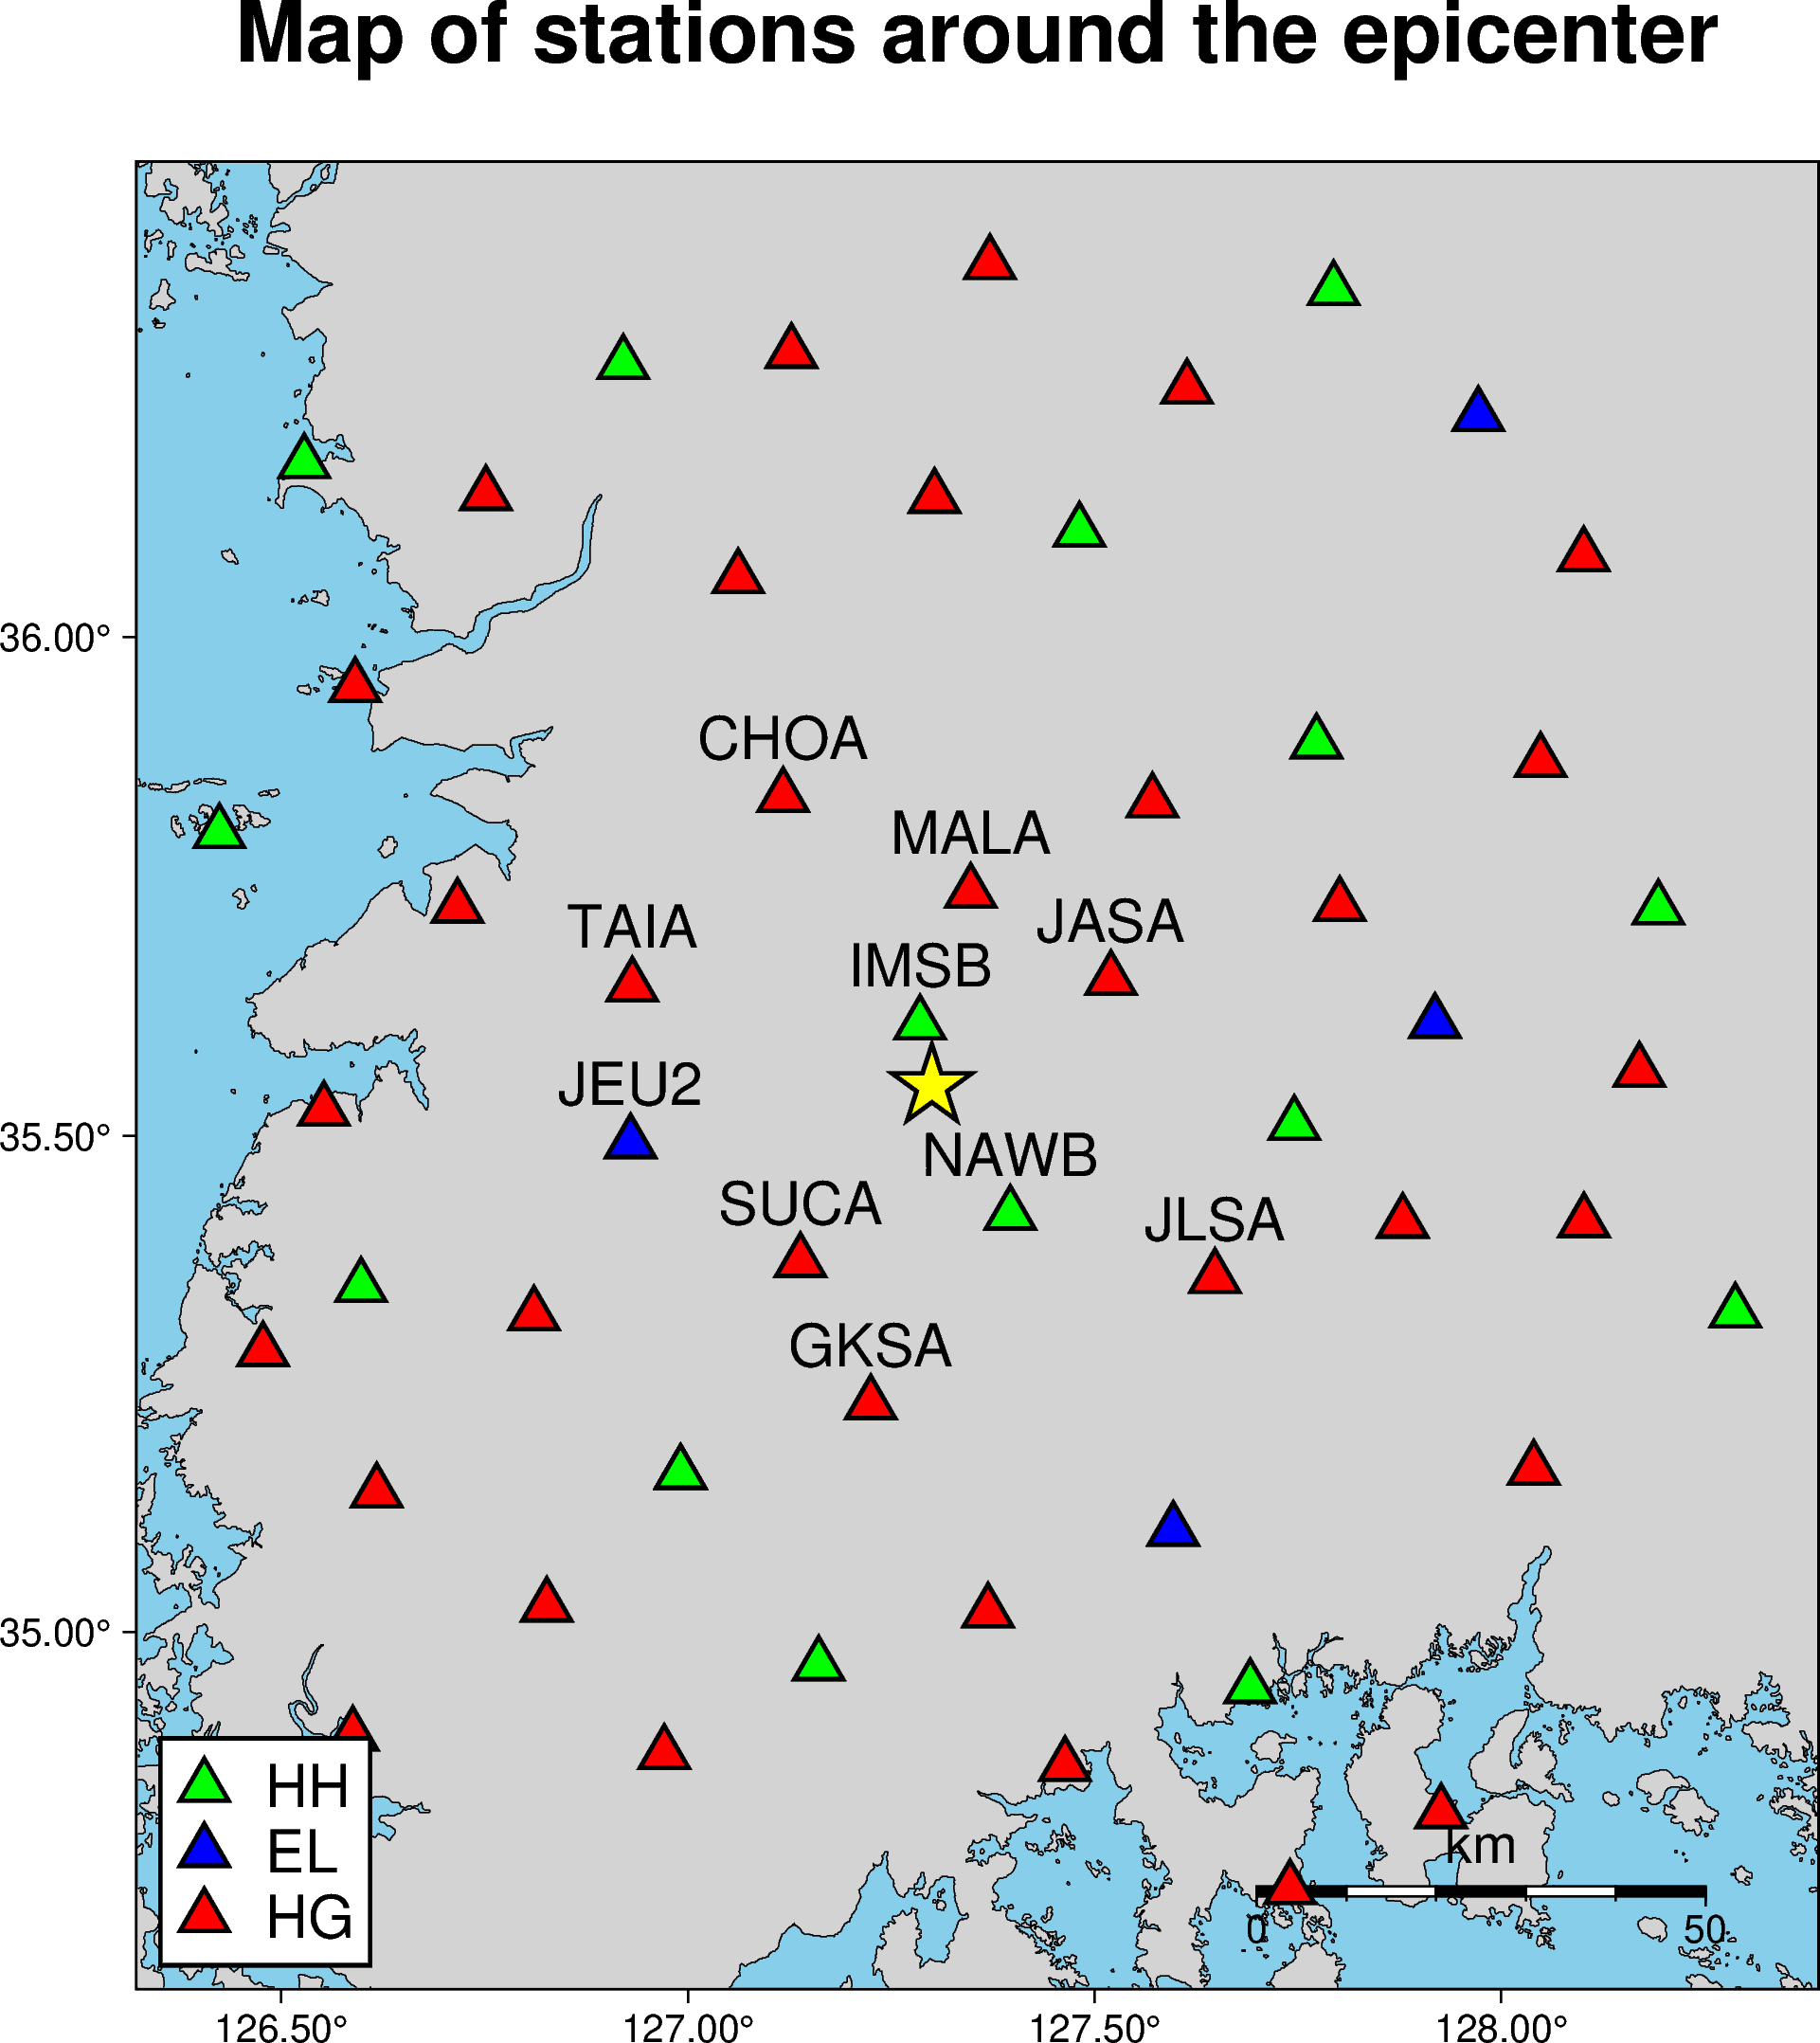

In [11]:
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xx", MAP_FRAME_TYPE="plain")

evla, evlo=35.55, 127.30
region=[used_station_table["Longitude"].min()-0.1, used_station_table["Longitude"].max()+0.1, used_station_table["Latitude"].min()-0.1, used_station_table["Latitude"].max()+0.1]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Map of stations around the epicenter"'])
fig.coast(land="lightgray", water="skyblue" ,shorelines=True, map_scale=f"n0.80/0.05+f+l+c{evlo}/{evla}+w50.0")

# Plot stations
fig.plot(x=used_station_table[used_station_table["Sensor"]=="HH"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="HH"]["Latitude"], style="t0.5c", fill="green", pen="1p,black", label="HH")
fig.plot(x=used_station_table[used_station_table["Sensor"]=="EL"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="EL"]["Latitude"], style="t0.5c", fill="blue", pen="1p,black", label="EL")
fig.plot(x=used_station_table[used_station_table["Sensor"]=="HG"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="HG"]["Latitude"], style="t0.5c", fill="red", pen="1p,black", label="HG")

for i in range(len(used_station_table)):
    code=used_station_table["Code"][i]
    stla, stlo=used_station_table["Latitude"][i], used_station_table["Longitude"][i]
    epidist=gps2dist_azimuth(evla, evlo, stla, stlo)[0]/1000
    if epidist<=40:
        fig.text(x=used_station_table["Longitude"][i], y=used_station_table["Latitude"][i]+0.06, text=code, font="15p")

# Plot epicenter
fig.plot(x=evlo, y=evla, style="a0.75c", fill="yellow", pen="1p,black")

with pmt.config(FONT_ANNOT_PRIMARY="15p"):
    fig.legend(position="JBL+jBL+o0.2c", box='+gwhite+p1p')

fig.show(width=600)

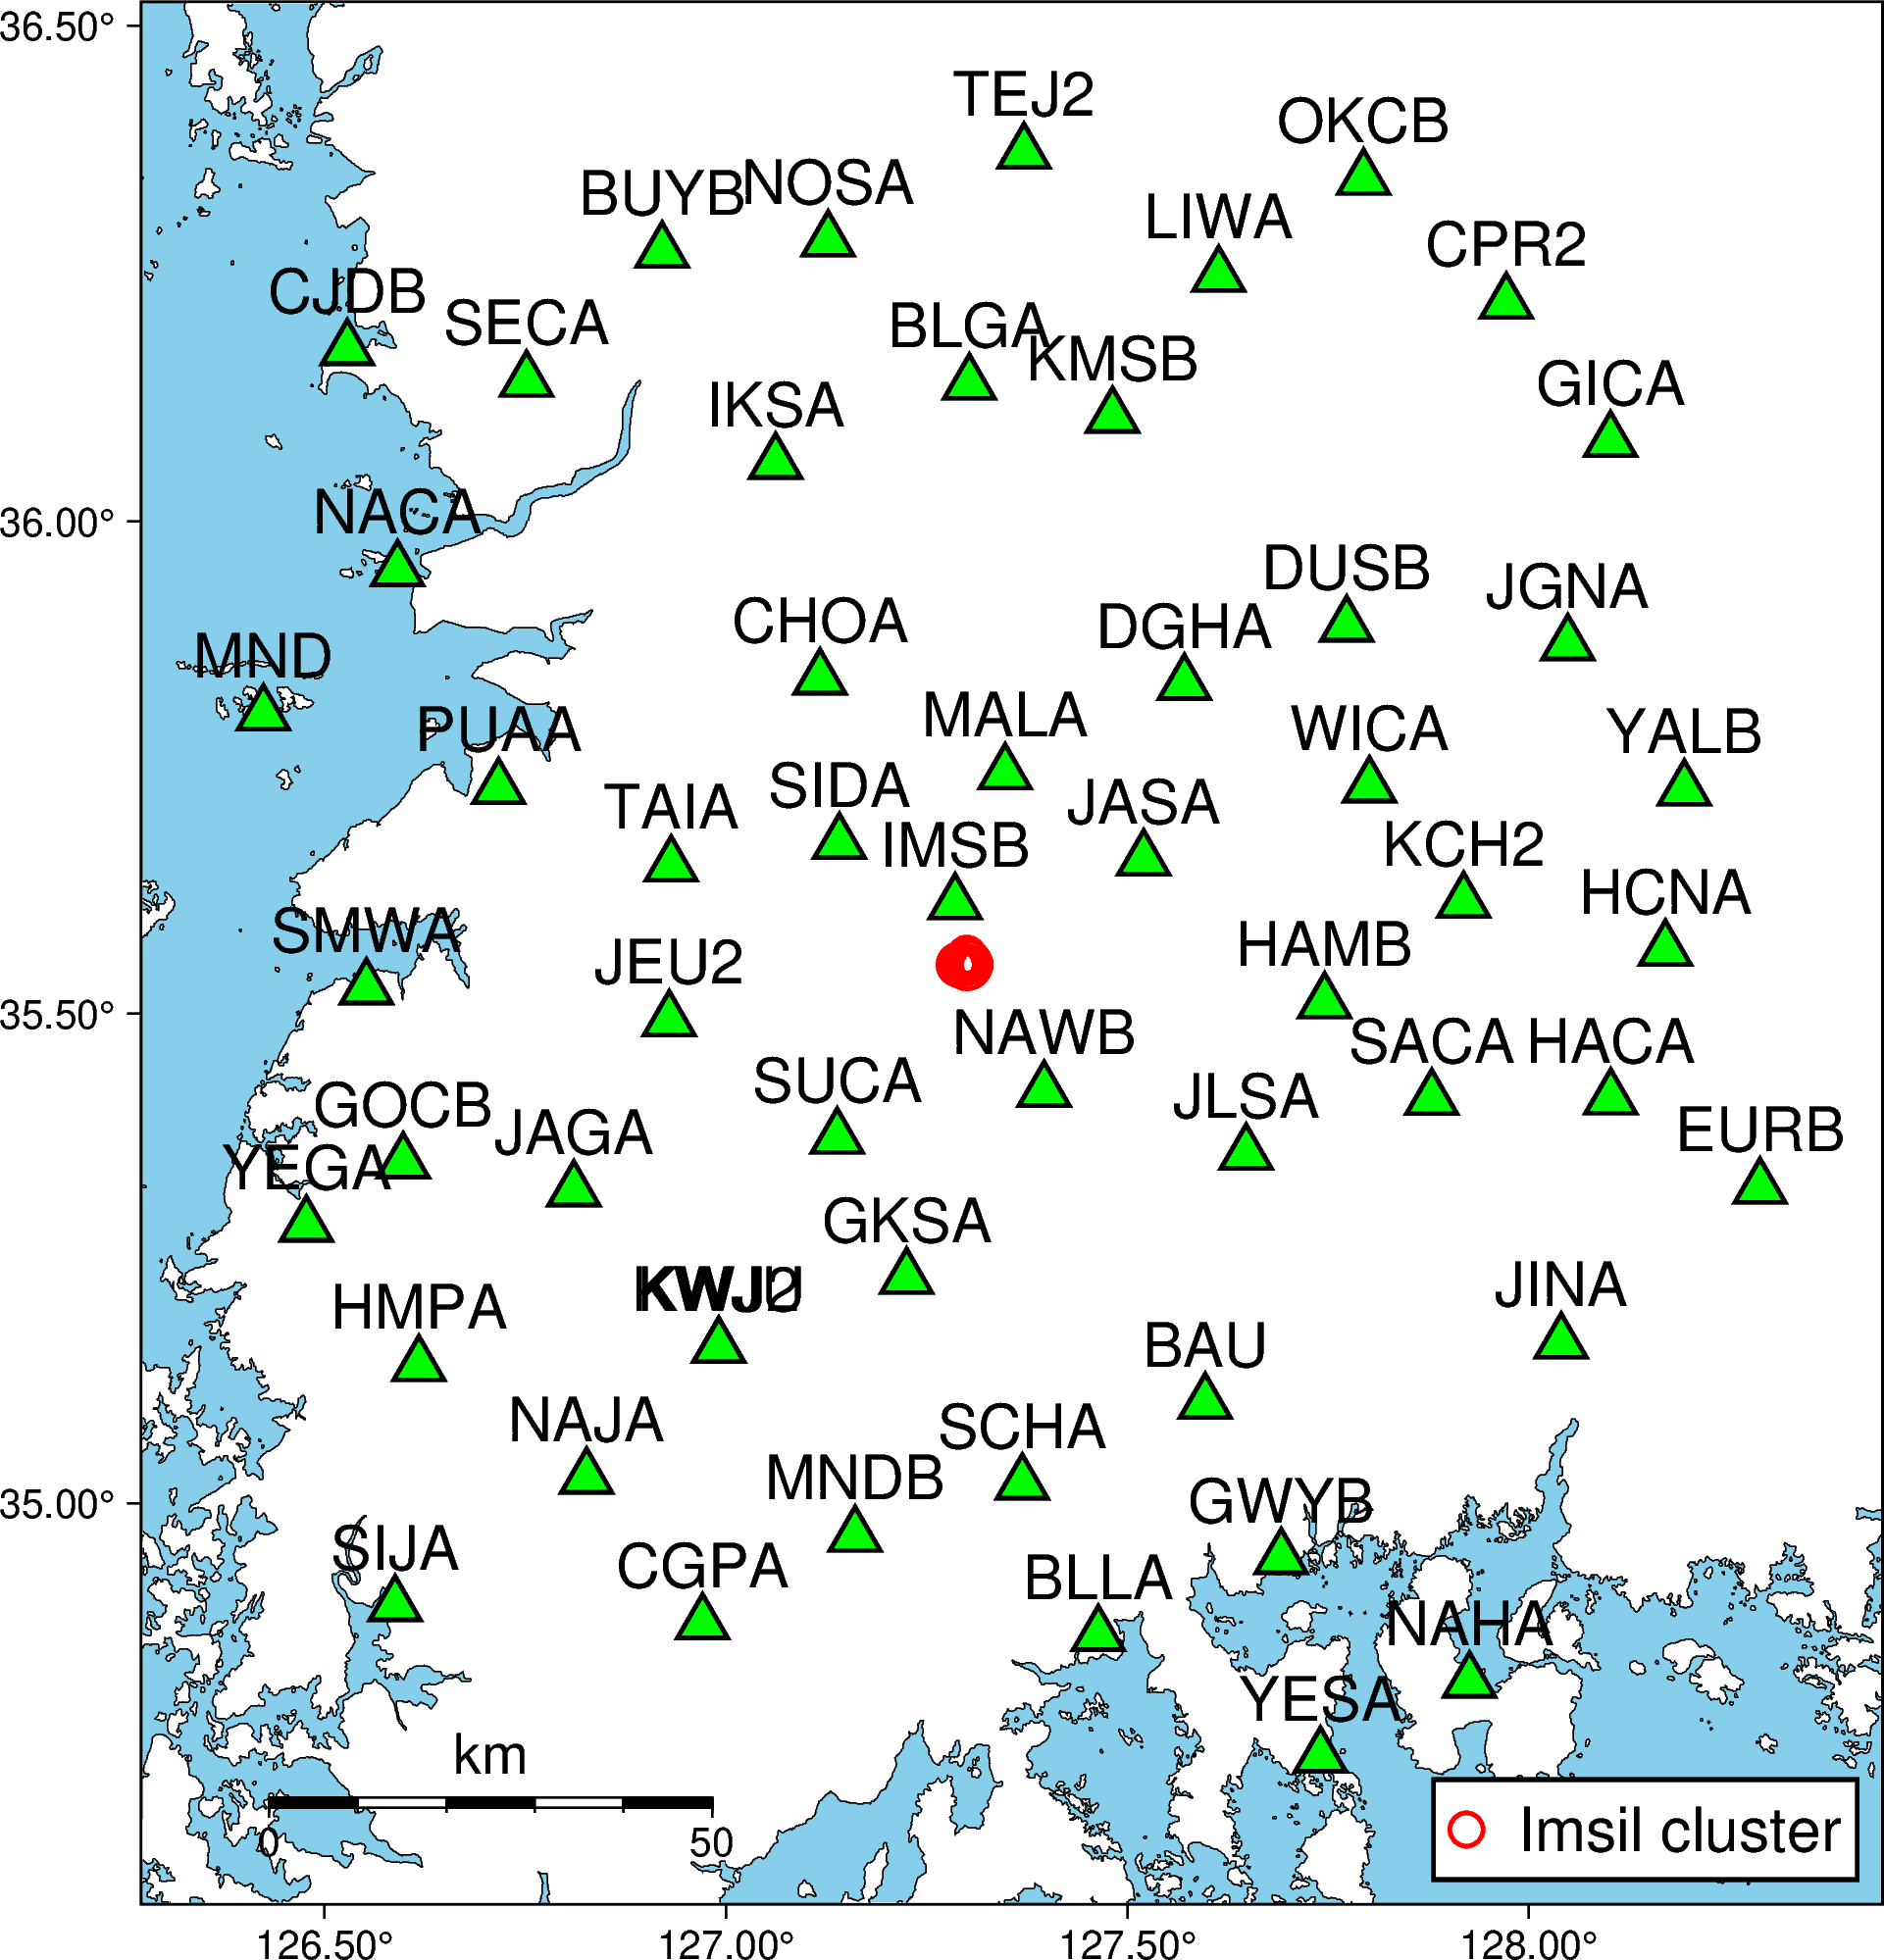

In [27]:
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xx", MAP_FRAME_TYPE="plain")

evla, evlo=35.55, 127.30
region=[used_station_table["Longitude"].min()-0.15, used_station_table["Longitude"].max()+0.15, used_station_table["Latitude"].min()-0.15, used_station_table["Latitude"].max()+0.15]

fig.basemap(region=region, projection="M15c", frame=["a"])
fig.coast(land="white", water="skyblue" ,shorelines=True, map_scale=f"n0.20/0.05+f+l+c{evlo}/{evla}+w50.0")

# Plot stations
fig.plot(x=used_station_table[used_station_table["Sensor"]=="HH"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="HH"]["Latitude"], style="t0.5c", fill="green", pen="1p,black")
fig.plot(x=used_station_table[used_station_table["Sensor"]=="EL"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="EL"]["Latitude"], style="t0.5c", fill="green", pen="1p,black")
fig.plot(x=used_station_table[used_station_table["Sensor"]=="HG"]["Longitude"], y=used_station_table[used_station_table["Sensor"]=="HG"]["Latitude"], style="t0.5c", fill="green", pen="1p,black")

for i in range(len(used_station_table)):
    code, sensor=used_station_table["Code"][i], used_station_table["Sensor"][i]
    stla, stlo=used_station_table["Latitude"][i], used_station_table["Longitude"][i]
    fig.text(x=used_station_table["Longitude"][i], y=used_station_table["Latitude"][i]+0.06, text=code, font="15p")
    # if sensor=="HH":
    #     fig.text(x=used_station_table["Longitude"][i], y=used_station_table["Latitude"][i]+0.06, text=code, font="15p")

# Plot epicenter
for i in range(len(imsil_catalog)):
    csize=0.1*np.exp(0.75*imsil_catalog["Magnitude"][i])
    if i==0:
        fig.plot(x=imsil_catalog["Longitude"][i], y=imsil_catalog["Latitude"][i], style=f"c{csize}c", pen="1p,red", label="Imsil cluster")
    else:
        fig.plot(x=imsil_catalog["Longitude"][i], y=imsil_catalog["Latitude"][i], style=f"c{csize}c", pen="1p,red")

with pmt.config(FONT_ANNOT_PRIMARY="15p"):
    fig.legend(position="JBR+jBR+o0.2c", box='+gwhite+p1p')

# fig.savefig("Station_map.pdf", dpi=500)
fig.show(width=600)